Step 4.1 – Install libraries

In [1]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn imbalanced-learn joblib

Step 4.2 – Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.preprocessing import RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    ConfusionMatrixDisplay
)

from sklearn.utils.class_weight import compute_class_weight

import joblib
import os

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


Step 4.3 – Upload dataset

In [3]:
from google.colab import files

uploaded = files.upload()

Saving creditcard.csv to creditcard.csv


Load the dataset:

In [4]:
df = pd.read_csv("creditcard.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Step 4.4 – Initial data inspection



In [5]:
print("Dataset Information")

df.info()

print("\nFirst 5 Rows")
display(df.head())

print("\nLast 5 Rows")
display(df.tail())

print("\nDataset Shape")
print(df.shape)

print("\nColumn Names")
print(df.columns.tolist())

print("\nStatistical Summary")
display(df.describe().T)

Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  flo

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Last 5 Rows


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0
284806,172792.0,-0.533413,-0.189733,0.703337,-0.506271,-0.012546,-0.649617,1.577006,-0.414650,0.486180,...,0.261057,0.643078,0.376777,0.008797,-0.473649,-0.818267,-0.002415,0.013649,217.00,0



Dataset Shape
(284807, 31)

Column Names
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Statistical Summary


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


Step 4.5 – Missing value analysis

In [6]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (
        missing_values / len(df)
    ) * 100
})

display(missing_summary.sort_values(
    "Missing Values",
    ascending=False
))

print("Total missing values:", df.isnull().sum().sum())

,Missing Values,Missing Percentage
Time,0,0.0
V1,0,0.0
V2,0,0.0
V3,0,0.0
V4,0,0.0
V5,0,0.0
V6,0,0.0
V7,0,0.0
V8,0,0.0
V9,0,0.0


Total missing values: 0


Step 4.6 – Duplicate analysis

In [7]:
print("Total duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Shape after duplicate removal:", df.shape)

Total duplicate rows: 1081
Shape after duplicate removal: (283726, 31)


Step 4.7 – Data type validation

In [8]:
print(df.dtypes)

print("\nClass column values:")
print(df["Class"].value_counts())

Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

Class column values:
Class
0    283253
1       473
Name: count, dtype: int64


In [9]:
assert df["Class"].isin([0, 1]).all()
assert df["Amount"].ge(0).all()

print("Data validation completed!")

Data validation completed!


# **Exploratory Data Analysis (EDA)**

5.1 Fraud vs legitimate transactions

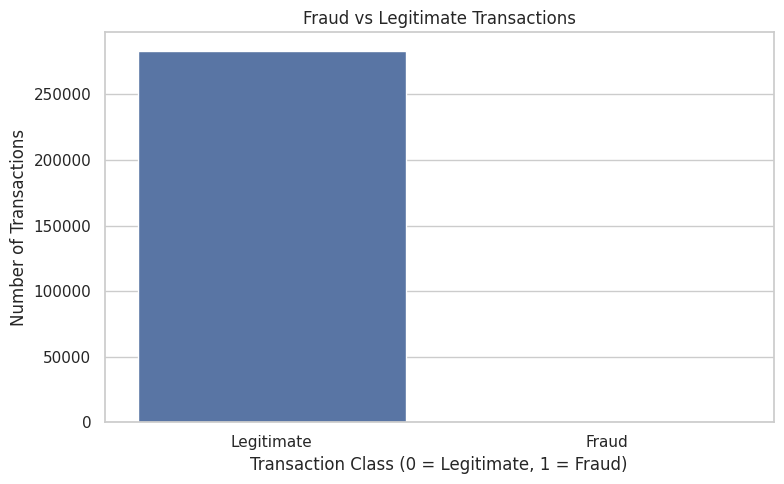

In [10]:
class_counts = df["Class"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("Fraud vs Legitimate Transactions")
plt.xlabel("Transaction Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")

plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.tight_layout()
plt.show()

5.2 Calculate fraud percentage

In [11]:
total_transactions = len(df)

fraud_count = (df["Class"] == 1).sum()
legitimate_count = (df["Class"] == 0).sum()

fraud_percentage = (
    fraud_count / total_transactions
) * 100

print("Total Transactions:", total_transactions)
print("Legitimate Transactions:", legitimate_count)
print("Fraud Transactions:", fraud_count)

print("Fraud Percentage:", round(fraud_percentage, 4), "%")

Total Transactions: 283726
Legitimate Transactions: 283253
Fraud Transactions: 473
Fraud Percentage: 0.1667 %


5.3 Transaction amount distribution

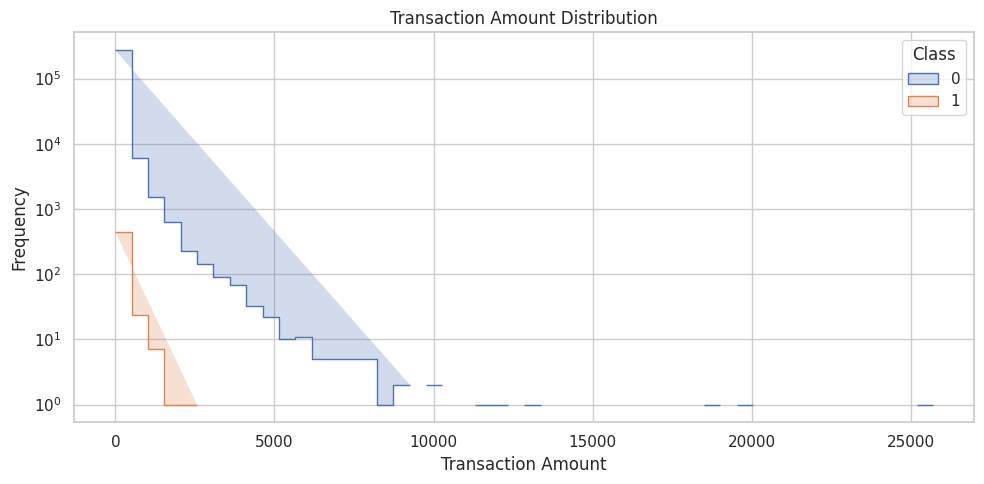

In [12]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Amount",
    hue="Class",
    bins=50,
    log_scale=(False, True),
    element="step"
)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

5.4 Transaction time analysis

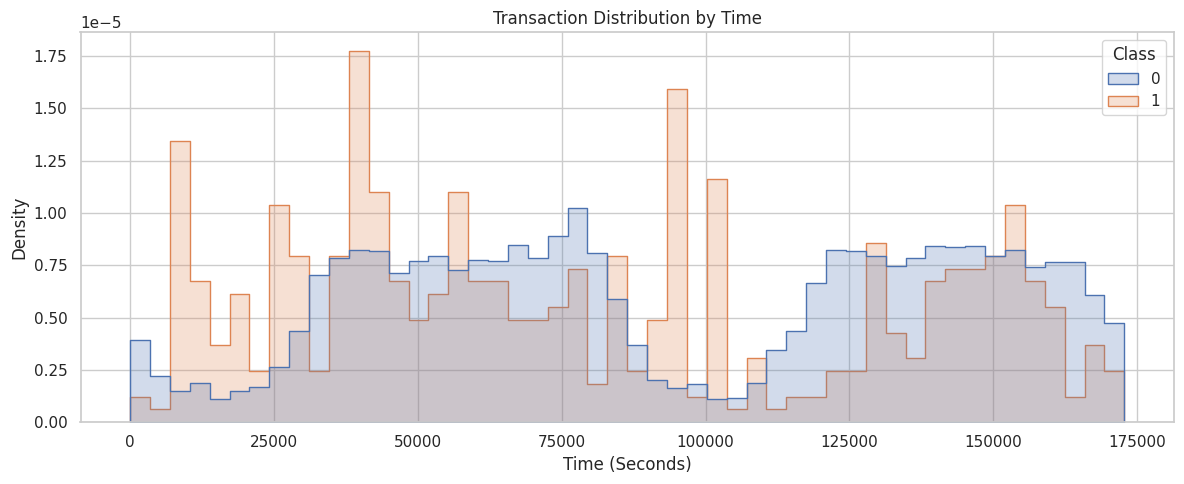

In [13]:
plt.figure(figsize=(12, 5))

sns.histplot(
    data=df,
    x="Time",
    hue="Class",
    bins=50,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Transaction Distribution by Time")
plt.xlabel("Time (Seconds)")
plt.ylabel("Density")

plt.tight_layout()
plt.show()

5.5 Correlation analysis

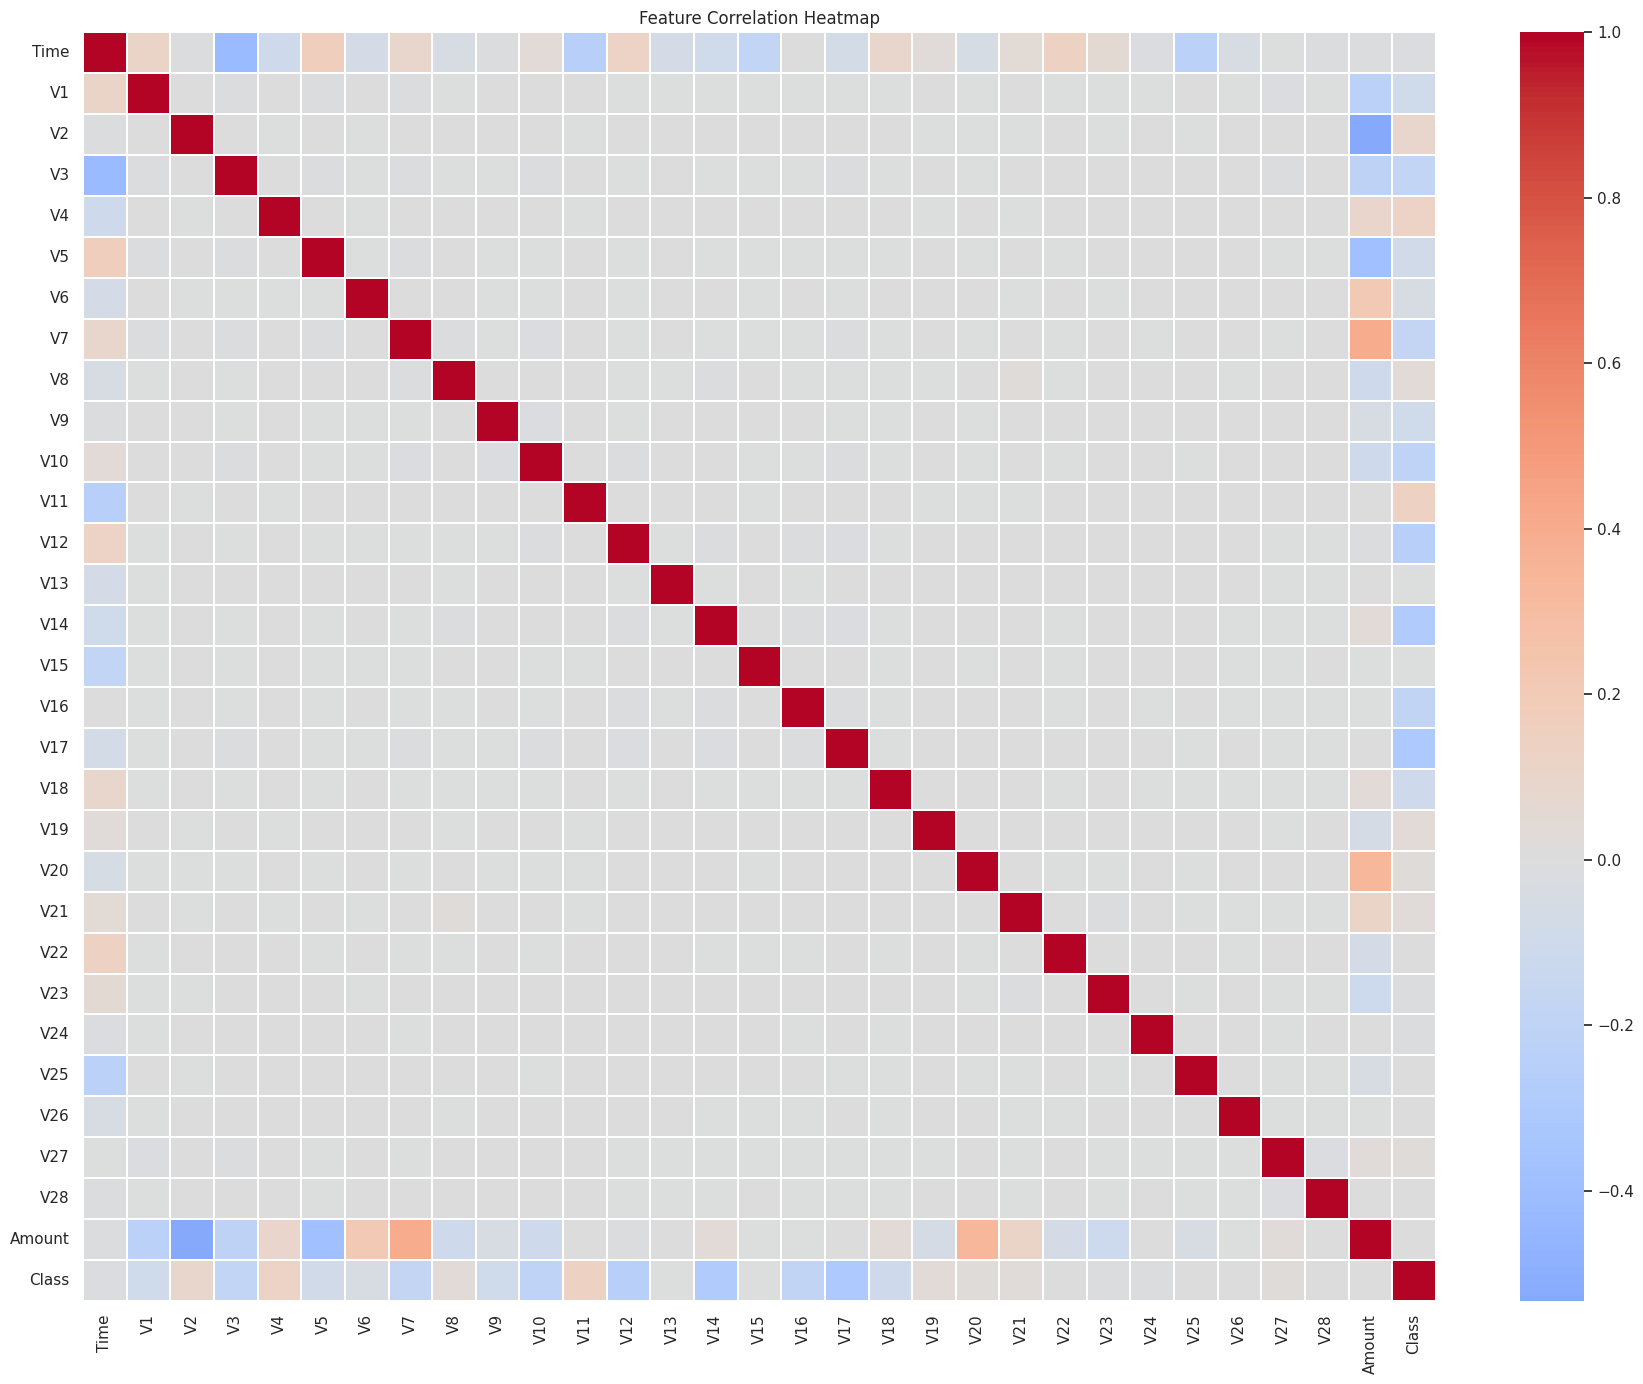

In [14]:
plt.figure(figsize=(18, 14))

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    linewidths=0.1
)

plt.title("Feature Correlation Heatmap")

plt.tight_layout()
plt.show()

5.6 Fraud transaction amount comparison

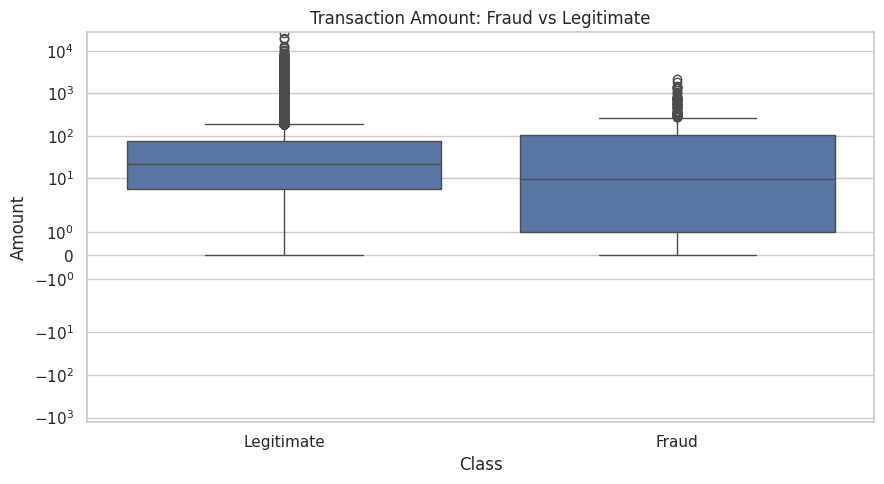

In [15]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Class",
    y="Amount"
)

plt.title("Transaction Amount: Fraud vs Legitimate")
plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.yscale("symlog")

plt.tight_layout()
plt.show()

5.7 EDA summary

In [16]:
eda_summary = df.groupby("Class").agg(
    Transaction_Count=("Class", "count"),
    Average_Amount=("Amount", "mean"),
    Median_Amount=("Amount", "median"),
    Maximum_Amount=("Amount", "max")
)

display(eda_summary)

,Transaction_Count,Average_Amount,Median_Amount,Maximum_Amount
Class,,,,
0,283253,88.413575,22.00,25691.16
1,473,123.871860,9.82,2125.87


# **6. Feature engineering and preprocessing**

6.1 Separate features and target

In [17]:
X = df.drop("Class", axis=1)
y = df["Class"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (283726, 30)
Target shape: (283726,)


6.2 Train-test split

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training features: (226980, 30)
Testing features: (56746, 30)

Training class distribution:
Class
0    226602
1       378
Name: count, dtype: int64

Testing class distribution:
Class
0    56651
1       95
Name: count, dtype: int64


6.3 Preprocessing pipeline

In [19]:
numeric_features = ["Time", "Amount"]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "scaled",
            RobustScaler(),
            numeric_features
        )
    ],
    remainder="passthrough"
)

# **7. Machine learning model development**

7.1 Logistic Regression

In [20]:
lr_model = Pipeline([
    ("preprocessor", preprocessor),
    (
        "classifier",
        LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        )
    )
])

lr_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


7.2 Random Forest

In [21]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=150,
            max_depth=15,
            min_samples_split=5,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    )
])

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


7.3 Generate predictions

In [22]:
lr_predictions = lr_model.predict(X_test)
rf_predictions = rf_model.predict(X_test)

lr_probabilities = lr_model.predict_proba(X_test)[:, 1]
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

7.4 Model evaluation

In [23]:
def evaluate_model(name, y_true, predictions, probabilities):

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    print("Accuracy:", accuracy_score(y_true, predictions))
    print("Precision:", precision_score(
        y_true, predictions, zero_division=0
    ))
    print("Recall:", recall_score(
        y_true, predictions, zero_division=0
    ))
    print("F1 Score:", f1_score(
        y_true, predictions, zero_division=0
    ))
    print("ROC-AUC:", roc_auc_score(
        y_true, probabilities
    ))
    print("PR-AUC:", average_precision_score(
        y_true, probabilities
    ))

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        predictions,
        zero_division=0
    ))

evaluate_model(
    "Logistic Regression",
    y_test,
    lr_predictions,
    lr_probabilities
)

evaluate_model(
    "Random Forest",
    y_test,
    rf_predictions,
    rf_probabilities
)


Logistic Regression
Accuracy: 0.9752405455891164
Precision: 0.05623306233062331
Recall: 0.8736842105263158
F1 Score: 0.10566518141311267
ROC-AUC: 0.9657099006010019
PR-AUC: 0.6719386121313643

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.06      0.87      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.98      0.99     56746


Random Forest
Accuracy: 0.9994713283755683
Precision: 0.9333333333333333
Recall: 0.7368421052631579
F1 Score: 0.8235294117647058
ROC-AUC: 0.9614696261226401
PR-AUC: 0.801220215380699

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.93      0.74      0.82        95

    accuracy                           1.00     56746
   macro avg       0.97      0

7.5 Confusion matrix

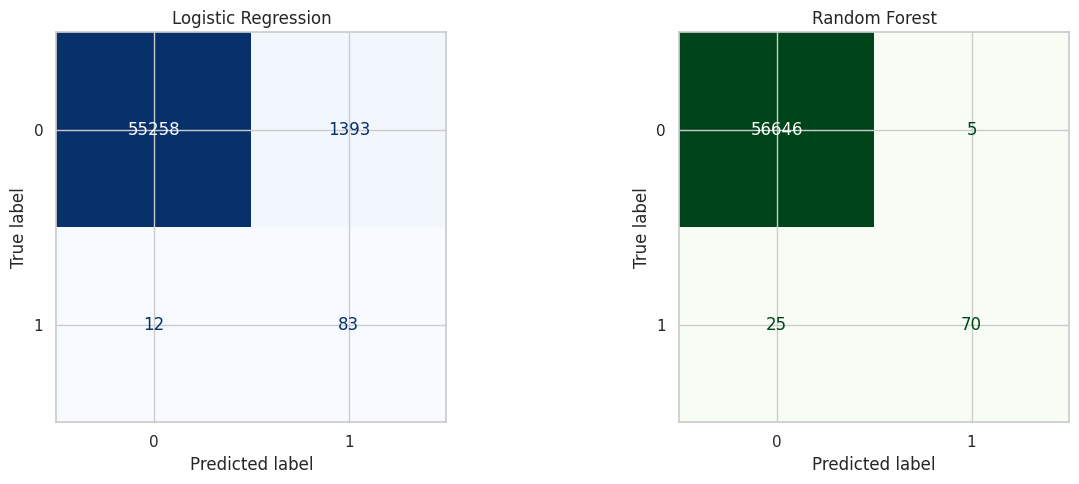

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    lr_predictions,
    ax=axes[0],
    cmap="Blues",
    colorbar=False
)

axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_predictions,
    ax=axes[1],
    cmap="Greens",
    colorbar=False
)

axes[1].set_title("Random Forest")

plt.tight_layout()
plt.show()

7.6 ROC curve

<Figure size 800x600 with 0 Axes>

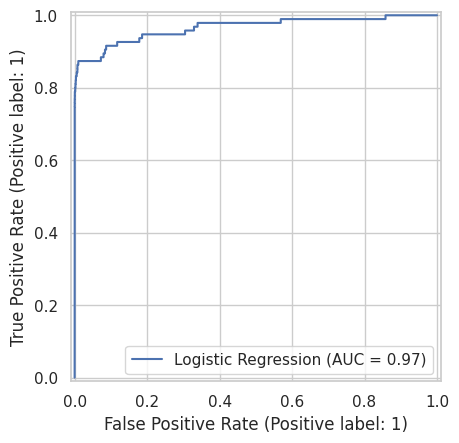

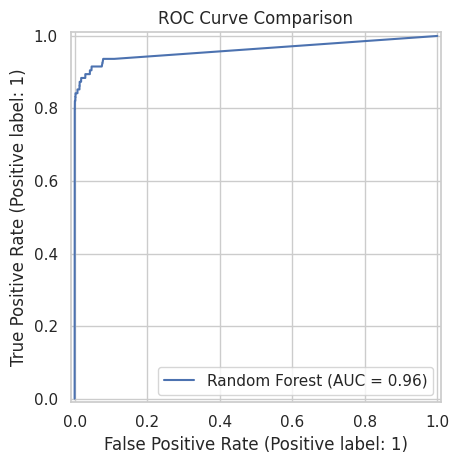

In [25]:
from sklearn.metrics import RocCurveDisplay

plt.figure(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test,
    lr_probabilities,
    name="Logistic Regression"
)

RocCurveDisplay.from_predictions(
    y_test,
    rf_probabilities,
    name="Random Forest"
)

plt.title("ROC Curve Comparison")
plt.tight_layout()
plt.show()

7.7 Precision-recall curve

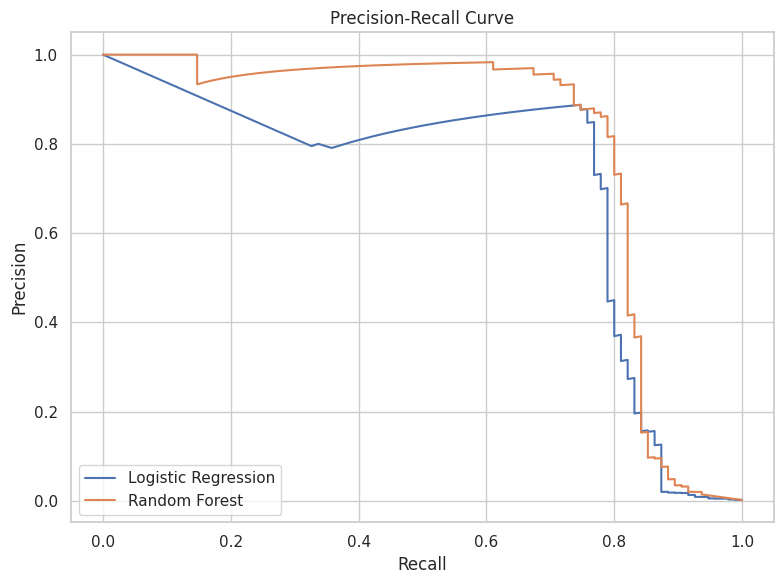

In [26]:
plt.figure(figsize=(8, 6))

for name, probabilities in [
    ("Logistic Regression", lr_probabilities),
    ("Random Forest", rf_probabilities)
]:
    precision, recall, thresholds = precision_recall_curve(
        y_test,
        probabilities
    )

    plt.plot(recall, precision, label=name)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.tight_layout()
plt.show()

# **8. Threshold optimization and model validation**

8.1 Create validation dataset

In [27]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Model training set:", X_fit.shape)
print("Validation set:", X_val.shape)

Model training set: (181584, 30)
Validation set: (45396, 30)


8.2 Train validation model

In [28]:
validation_model = Pipeline([
    ("preprocessor", preprocessor),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=150,
            max_depth=15,
            min_samples_split=5,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    )
])

validation_model.fit(X_fit, y_fit)

val_probabilities = validation_model.predict_proba(X_val)[:, 1]

print("Validation model trained!")

Validation model trained!


8.3 Find a suitable classification threshold

In [29]:
thresholds = np.arange(0.05, 0.96, 0.05)

threshold_results = []

for threshold in thresholds:

    predictions = (
        val_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

best_threshold = threshold_df.loc[
    threshold_df["F1 Score"].idxmax(),
    "Threshold"
]

print("Selected validation threshold:", best_threshold)

,Threshold,Precision,Recall,F1 Score
0,0.05,0.290043,0.881579,0.436482
1,0.10,0.563025,0.881579,0.687179
2,0.15,0.736264,0.881579,0.802395
3,0.20,0.817073,0.881579,0.848101
4,0.25,0.890411,0.855263,0.872483
5,0.30,0.915493,0.855263,0.884354
6,0.35,0.915493,0.855263,0.884354
7,0.40,0.914286,0.842105,0.876712
8,0.45,0.913043,0.828947,0.868966
9,0.50,0.940299,0.828947,0.881119


Selected validation threshold: 0.3


8.4 Final model training

In [30]:
final_model = Pipeline([
    ("preprocessor", preprocessor),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=150,
            max_depth=15,
            min_samples_split=5,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    )
])

final_model.fit(X_train, y_train)

print("Final model trained successfully!")

Final model trained successfully!


8.5 Final test evaluation

In [31]:
final_probabilities = final_model.predict_proba(X_test)[:, 1]

final_predictions = (
    final_probabilities >= best_threshold
).astype(int)

evaluate_model(
    "Final Random Forest Model",
    y_test,
    final_predictions,
    final_probabilities
)


Final Random Forest Model
Accuracy: 0.9994008388256441
Precision: 0.8765432098765432
Recall: 0.7473684210526316
F1 Score: 0.8068181818181818
ROC-AUC: 0.9614696261226401
PR-AUC: 0.801220215380699

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.88      0.75      0.81        95

    accuracy                           1.00     56746
   macro avg       0.94      0.87      0.90     56746
weighted avg       1.00      1.00      1.00     56746



# **9. Feature importance analysis**

In [32]:
rf_classifier = final_model.named_steps["classifier"]

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_classifier.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.head(15))

,Feature,Importance
15,V15,0.181056
13,V13,0.128263
5,V5,0.103090
11,V11,0.094331
18,V18,0.091283
12,V12,0.089472
4,V4,0.055170
8,V8,0.031488
17,V17,0.028280
3,V3,0.023993


Visualization:

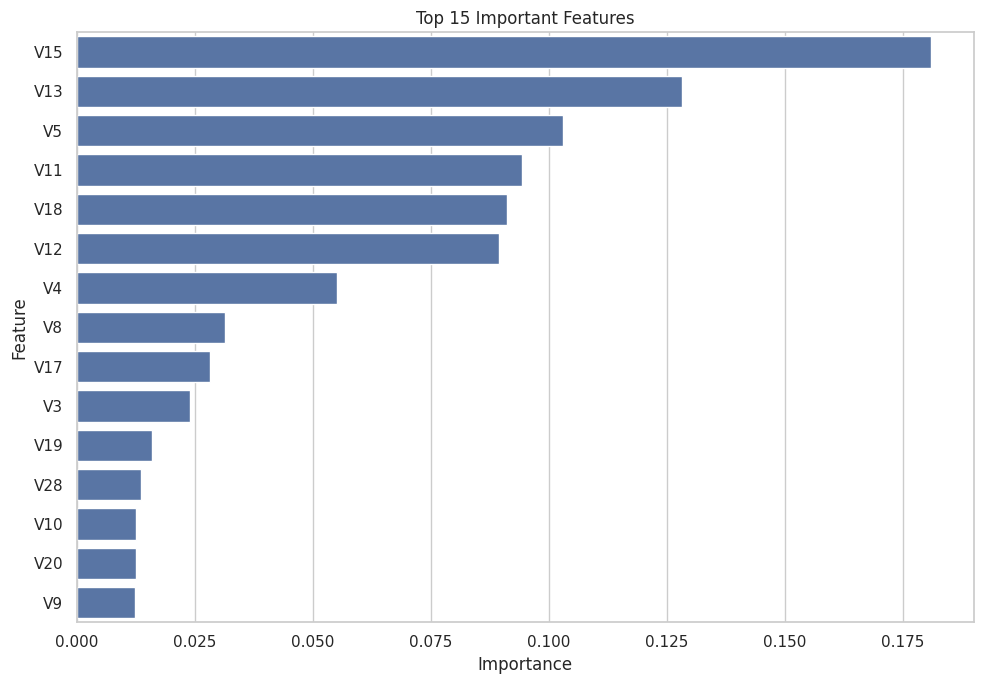

In [33]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features")
plt.tight_layout()
plt.show()

# **10. Save the trained model**

In [34]:
os.makedirs("artifacts", exist_ok=True)

joblib.dump(
    final_model,
    "artifacts/fraud_detection_model.pkl"
)

joblib.dump(
    best_threshold,
    "artifacts/fraud_threshold.pkl"
)

print("Model and threshold saved successfully!")

Model and threshold saved successfully!


11. Save project outputs

In [35]:
os.makedirs("outputs", exist_ok=True)

# Save model comparison
comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, lr_predictions),
        "Precision": precision_score(y_test, lr_predictions),
        "Recall": recall_score(y_test, lr_predictions),
        "F1 Score": f1_score(y_test, lr_predictions),
        "ROC-AUC": roc_auc_score(y_test, lr_probabilities),
        "PR-AUC": average_precision_score(y_test, lr_probabilities)
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf_predictions),
        "Precision": precision_score(y_test, rf_predictions),
        "Recall": recall_score(y_test, rf_predictions),
        "F1 Score": f1_score(y_test, rf_predictions),
        "ROC-AUC": roc_auc_score(y_test, rf_probabilities),
        "PR-AUC": average_precision_score(y_test, rf_probabilities)
    }
])

comparison.to_csv(
    "outputs/model_comparison.csv",
    index=False
)

feature_importance.to_csv(
    "outputs/feature_importance.csv",
    index=False
)

threshold_df.to_csv(
    "outputs/threshold_analysis.csv",
    index=False
)

print("Project outputs saved!")
display(comparison)

Project outputs saved!


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.975241,0.056233,0.873684,0.105665,0.96571,0.671939
1,Random Forest,0.999471,0.933333,0.736842,0.823529,0.96147,0.801220


11.1 Save final test predictions

In [36]:
test_results = X_test.copy()

test_results["Actual_Class"] = y_test
test_results["Predicted_Class"] = final_predictions
test_results["Fraud_Probability"] = final_probabilities

test_results.to_csv(
    "outputs/test_predictions.csv",
    index=False
)

print("Test predictions exported!")

Test predictions exported!


11.2 Download project artifacts

In [37]:
import shutil

shutil.make_archive(
    "fraud_detection_artifacts",
    "zip",
    ".",
    "artifacts"
)

files.download("fraud_detection_artifacts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
files.download("outputs/model_comparison.csv")
files.download("outputs/feature_importance.csv")
files.download("outputs/threshold_analysis.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>